# Notebook 29 · Descriptores corregidos, ablación y reentrenamiento real

Este cuaderno ejecuta el siguiente paso del NB28: **incorporar realmente los descriptores corregidos a modelos nuevos**, medir qué aporta cada uno y reajustar los modelos nacionales. También sustituye el catálogo inicial de dianas por un diseño prospectivo emparejado, con distancias verificables.

La hipótesis es comprobable, no una promesa de mejora: las interacciones sedimentarias/topográficas y espectrales pueden ayudar o empeorar el ranking. Se conservan los resultados completos en ambos casos.

**Diseño fijado antes de obtener resultados NB29:** ocho miembros, U:P=3:1 sin reemplazo, mismas semillas y particiones que NB27; cinco pliegues espaciales, siete rotaciones y tres pliegues internos con bloques de 50 km y buffer de 15 km. Endpoint principal: recuperación de depósitos en el 5% de celdas reservadas, comparando `max3_97` con `max3_95_ref`. La cartografía principal experimental se fija como `max3_97`, sin elegirla después de mirar el test.

Los territorios se han examinado en NB19–28. Se trata de un contraste exploratorio, no de un test externo nuevo. No se inventan nuevas mediciones analíticas, imágenes Sentinel-2 ni resultados de campo. Las covariables nuevas son interacciones de información cartográfica existente.

Implementación: `prospective_features.py`, `prospective_models.py` y `prospective_experiment.py`, en `src/geoau/`. Las celdas ejecutan los ajustes, muestran sus resultados y conservan los artefactos anteriores.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from geoau.prospective_experiment import ProspectiveExperiment
from geoau.prospective_features import NEW_FEATURES
from geoau.prospective_models import METHODS29, REFERENCES29

exp = ProspectiveExperiment(ROOT, output='reports/reentrenamiento_nb29_descriptores_y_piloto_20261022')
print('Python:', sys.executable)
print('Resultados:', exp.output)
print('Dominio:', len(exp.data.grid), '| P elegibles:', len(exp.data.positives))
display(pd.Series(exp.cfg).to_frame('Diseño fijado antes de evaluar NB29'))


2026-10-22T16:06:38+00:00 NB29: diseño fijado; ablaciones reales, 5 CV, 7 rotaciones y ajuste nacional


Python: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\.venv-fase-a\Scripts\python.exe
Resultados: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_nb29_descriptores_y_piloto_20261022
Dominio: 478443 | P elegibles: 664


,Diseño fijado antes de evaluar NB29
seed,42
bags,8
inner_folds,3
buffer_m,15000
weight_step,0.1
minimum_specialist_P,2
prediction_batch_size,25000
default_national_method,max3_97
selection_metric,inner_oof_average_precision
classifier,"{'n_estimators': 150, 'max_depth': 5, 'num_lea..."


## 1. Corregir la semántica antes de entrenar

El NB28 llamaba terrazas cuaternarias a `litologia_u000_fraccion`. Su leyenda real es una unidad mixta de areniscas, conglomerados, arcillas, calizas y evaporitas. El contexto de gravas/conglomerados/arenas/limos es **u012**. La edad cuaternaria u004 fue excluida del modelo inicial porque duplica exactamente u012; añadir ambas como observaciones distintas exageraría la información disponible.

El GPKG auxiliar de recintos cuaternarios se audita: sus registros tienen el mismo descriptor genérico y código geomorfológico 0. No permite identificar terrazas fluviales con respaldo suficiente y no se incorpora.

Las tipologías conservan la revisión del NB27: desconocidos en el global, siete celdas mixtas y epitermal limitado a los dos depósitos documentados de Rodalquilar. Primario no equivale exclusivamente a orogénico o varisco.

In [2]:
display(exp.audit_labels())
display(exp.prepare_features())
display(pd.read_csv(exp.output / 'contrato_descriptores_nb29.csv'))
display(exp.X[NEW_FEATURES].describe())
print('Número de variables:', len(exp.X.columns))
print('Ausentes conservados:')
display(exp.X[NEW_FEATURES].isna().sum().to_frame('sin_dato'))


2026-10-22T16:06:38+00:00 Auditoría de tipologías: [{"grupo":"primario","celdas_P":263},{"grupo":"primario_otro","celdas_P":259},{"grupo":"aluvial","celdas_P":310},{"grupo":"epitermal","celdas_P":4},{"grupo":"no_resuelto","celdas_P":98},{"grupo":"mixto","celdas_P":7}]


,grupo,celdas_P
0,primario,263
1,primario_otro,259
2,aluvial,310
3,epitermal,4
4,no_resuelto,98
5,mixto,7


2026-10-22T16:06:46+00:00 Matriz NB29: 478443 celdas y 97 variables; 95 originales idénticas


,source,interpretation,decision
0,litologia_u000,"Areniscas, conglomerados, arcillas; calizas y ...",No se utiliza como sinónimo de terraza ni de s...
1,litologia_u012,"Gravas, conglomerados, arenas y limos",Contexto sedimentario amplio; no certifica ter...
2,edades_u004,CUATERNARIO,Duplicación exacta de u012 en el dominio: True...
3,cuaternariorecintos.gpkg,"{""n"": 44464, ""descriptions"": [[""Recinto auxili...",No se añade: no distingue terrazas/aluviales c...


,variable,formula,meaning
0,trampa_aluvial_contextual_nb29,exp(-dist_cauce/300)*exp(-pendiente/6)*(0.25+0...,Interacción de contexto sedimentario y posició...
1,alteracion_suelo_expuesto_nb29,"log1p(max(clip(SWIR,0,4)-1,0))*log1p(max(clip(...",Proxy regional MODIS con atenuación vegetal; s...


,trampa_aluvial_contextual_nb29,alteracion_suelo_expuesto_nb29
count,4.636480e+05,477793.000000
mean,2.352527e-02,0.108739
std,7.713789e-02,0.041398
min,1.668575e-17,0.000000
25%,1.725870e-06,0.085155
50%,2.168373e-04,0.113135
75%,7.834032e-03,0.136482
max,9.938675e-01,0.450342


Número de variables: 97
Ausentes conservados:


,sin_dato
trampa_aluvial_contextual_nb29,14795
alteracion_suelo_expuesto_nb29,650


## 2. Hipótesis físicas y límites de las dos covariables

**Aluvial contextual:**

\[
A=\exp(-d_{cauce}/300)\exp(-pendiente/6)(0.25+0.75f_{u012})\exp[-\max(TPI_{1km},0)/50].
\]

Usa contexto sedimentario, cercanía a cauces, pendiente y posición respecto al relieve local. El TPI positivo atenúa posiciones elevadas; no se lo denomina energía hidráulica, área aportante ni terraza observada. Las escalas y el término de fondo son constantes heurísticas fijadas antes de evaluar, no ajustadas con el test.

**Alteración con suelo expuesto:**

\[
S=\log[1+\max(clip(SWIR,0,4)-1,0)]\log[1+\max(clip(Fe,0,5)-1,0)](1-clip(NDVI,0,1))^2.
\]

Se atenúan vegetación y extremos mediante una interacción de ratios MODIS. No es una medición de mineral ni una máscara QA. No aumenta la resolución del sensor ni reemplaza análisis de laboratorio. Los ausentes permanecen ausentes hasta la imputación de cada miembro; las estadísticas pathfinder y el preprocesamiento se aprenden exclusivamente dentro de su entrenamiento.

La ganancia de importancia interna de una covariable no prueba que mejore la generalización. Esa afirmación se comprueba mediante la ablación y la recuperación territorial.

In [3]:
contrastes = pd.DataFrame([
    {'procedimiento': 'mono95_ref', 'variables': 95, 'objetivo': 'control NB27 verificado'},
    {'procedimiento': 'mono96_aluvial', 'variables': 96, 'objetivo': 'aislar descriptor aluvial'},
    {'procedimiento': 'mono96_espectral', 'variables': 96, 'objetivo': 'aislar descriptor espectral'},
    {'procedimiento': 'mono97', 'variables': 97, 'objetivo': 'efecto conjunto y contraste de interacción'},
    {'procedimiento': 'max3_97 / fusion3_97', 'variables': 97, 'objetivo': 'mismos componentes; cambia la agregación'},
    {'procedimiento': 'max3_95_ref / fusion3_95_ref', 'variables': 95, 'objetivo': 'control de arquitectura NB27'},
    {'procedimiento': 'regla_geologica_ref', 'variables': '-', 'objetivo': 'referencia física fijada sin aprender del test'},
])
display(contrastes)
print('El control se reutiliza con hashes y entorno verificados; los modelos de 96/97 variables se entrenan realmente.')


,procedimiento,variables,objetivo
0,mono95_ref,95,control NB27 verificado
1,mono96_aluvial,96,aislar descriptor aluvial
2,mono96_espectral,96,aislar descriptor espectral
3,mono97,97,efecto conjunto y contraste de interacción
4,max3_97 / fusion3_97,97,mismos componentes; cambia la agregación
5,max3_95_ref / fusion3_95_ref,95,control de arquitectura NB27
6,regla_geologica_ref,-,referencia física fijada sin aprender del test


El control se reutiliza con hashes y entorno verificados; los modelos de 96/97 variables se entrenan realmente.


## 3. Entrenamiento y evaluación espacial real

Se guardan todas las filas de entrenamiento de cada miembro y se comparan con las del control. La única diferencia entre los modelos globales es el conjunto de columnas. Las ramas de 97 variables usan también las mismas muestras y semillas que sus ramas equivalentes del NB27.

Las CDF se ajustan con predicciones U fuera de pliegue dentro del entrenamiento. Los pesos de fusión se eligen con referencias cruzadas entre pliegues internos y AP P/U, conservando peso global >=0,1. Esta AP es un proxy de discriminación y no optimiza directamente recuperación territorial por área. No se utilizan estadísticas de las etiquetas externas ni normalización min/max del test.

Los scores son rankings relativos. La AP de la muestra P/U y Brier no estiman prevalencia ni probabilidad física de descubrir oro.

In [4]:
cv = exp.evaluate_cv()
display(cv[['method', 'roc_auc', 'average_precision', 'positive_cell_recovery_at_05', 'positive_cell_recovery_at_10']])
base_cv = cv.set_index('method').loc['mono95_ref']
delta_cv = cv.loc[cv.method.isin(['mono96_aluvial', 'mono96_espectral', 'mono97']), ['method', 'roc_auc', 'average_precision']].copy()
delta_cv['delta_auc_vs95'] = delta_cv.roc_auc - base_cv.roc_auc
delta_cv['delta_ap_vs95'] = delta_cv.average_precision - base_cv.average_precision
display(delta_cv)


2026-10-22T16:06:47+00:00 Iniciando cv/0: 450 P; 503 celdas de evaluación


2026-10-22T16:07:10+00:00 cv/0/inner_0: P=358, 40 ajustes nuevos, 8.3s


2026-10-22T16:07:21+00:00 cv/0/inner_1: P=212, 40 ajustes nuevos, 6.6s


2026-10-22T16:07:30+00:00 cv/0/inner_2: P=109, 40 ajustes nuevos, 4.5s


2026-10-22T16:07:44+00:00 cv/0/outer: P=450, 40 ajustes nuevos, 9.9s


...

2026-10-22T16:11:21+00:00 cv/4/inner_2: P=249, 40 ajustes nuevos, 6.6s


2026-10-22T16:11:35+00:00 cv/4/outer: P=444, 40 ajustes nuevos, 9.1s


2026-10-22T16:11:36+00:00 CV espacial 5/5 terminada


,method,roc_auc,average_precision,positive_cell_recovery_at_05,positive_cell_recovery_at_10
0,mono95_ref,0.894895,0.702020,0.157393,0.311606
1,max3_95_ref,0.889989,0.687164,0.160572,0.313196
2,fusion3_95_ref,0.894097,0.699863,0.155803,0.310016
3,regla_geologica_ref,0.785134,0.453527,0.082671,0.186010
4,mono96_aluvial,0.895153,0.701853,0.158983,0.310016
5,mono96_espectral,0.894276,0.698883,0.162162,0.310016
6,mono97,0.895629,0.702791,0.160572,0.311606
7,max3_97,0.889107,0.688273,0.160572,0.310016
8,fusion3_97,0.892204,0.698127,0.160572,0.311606


,method,roc_auc,average_precision,delta_auc_vs95,delta_ap_vs95
4,mono96_aluvial,0.895153,0.701853,0.000258,-0.000167
5,mono96_espectral,0.894276,0.698883,-0.000619,-0.003137
6,mono97,0.895629,0.702791,0.000734,0.000771


## 4. Recuperación de depósitos e incertidumbre

Se puntúan todas las celdas de las siete reservas y se seleccionan presupuestos exactos del 1/5/10/20%, con desempate por cell_id. Cada depósito se cuenta una sola vez.

La referencia aleatoria tiene en cuenta huellas multicelda, celdas compartidas y muestreo sin reemplazo. Se calcula la esperanza hipergeométrica exacta y se simulan 20.000 selecciones por presupuesto. Su intervalo nulo no es un intervalo de confianza de la probabilidad de descubrimiento.

La comparación pareada usa 10.000 remuestreos de los **siete grupos de rotación**, manteniendo juntas las observaciones territoriales de cada grupo. Es una estimación exploratoria con pocos grupos y territorios reutilizados. Las colas Monte Carlo no se presentan como una prueba confirmatoria ni se selecciona un presupuesto después de observar resultados.

In [5]:
rotaciones = exp.evaluate_rotations()
display(rotaciones[['method', 'n_deposits', 'captured_01', 'captured_05', 'captured_10', 'captured_20']])
display(pd.read_csv(exp.output / 'random_summary.csv'))
pareada = pd.read_csv(exp.output / 'paired_ablation_comparison.csv')
display(pareada.loc[pareada.budget_percent.eq(5)])
principal = pareada.loc[pareada.contrast.eq('max97_vs_max95') & pareada.budget_percent.eq(5)].iloc[0]
print(f"Contraste principal: {principal.delta_captured:+.0f} depósitos; intervalo de diferencia [{principal.ci025_pp:.2f}, {principal.ci975_pp:.2f}] puntos porcentuales")


2026-10-22T16:11:37+00:00 Iniciando rotation/0: 559 P; 9290 celdas de evaluación


2026-10-22T16:12:04+00:00 rotation/0/inner_0: P=198, 48 ajustes nuevos, 7.0s


2026-10-22T16:12:19+00:00 rotation/0/inner_1: P=348, 40 ajustes nuevos, 8.5s


2026-10-22T16:12:33+00:00 rotation/0/inner_2: P=325, 48 ajustes nuevos, 8.9s


2026-10-22T16:12:53+00:00 rotation/0/outer: P=559, 48 ajustes nuevos, 13.5s


...

2026-10-22T16:20:05+00:00 Rotación territorial 7/7 terminada; referencia aleatoria simulada


,method,n_deposits,captured_01,captured_05,captured_10,captured_20
0,mono95_ref,45,1,5,10,16
1,max3_95_ref,45,1,9,12,20
2,fusion3_95_ref,45,0,7,10,15
3,regla_geologica_ref,45,1,9,10,15
4,mono96_aluvial,45,1,4,10,16
5,mono96_espectral,45,1,4,11,16
6,mono97,45,1,5,10,16
7,max3_97,45,1,7,11,21
8,fusion3_97,45,1,4,11,15


,budget_percent,expected_deposits,simulation_mean,null_q025,null_q975,simulation_standard_error
0,1,1.315466,1.31455,0.0,4.0,0.007933
1,5,6.160566,6.16470,2.0,11.0,0.015760
2,10,11.434624,11.42130,6.0,17.0,0.019668
3,20,19.909472,19.89550,14.0,26.0,0.021833


,contrast,budget_percent,delta_captured,delta_recovery_pp,ci025_pp,ci975_pp,bootstrap_unit,n_clusters
7,aluvial_vs_95,5,-1,-2.222222,-6.976744,0.000000,rotation_group,7
8,espectral_vs_95,5,-1,-2.222222,-6.976744,0.000000,rotation_group,7
9,ambos_vs_95,5,0,0.000000,0.000000,0.000000,rotation_group,7
10,interaccion_descriptores,5,2,4.444444,0.000000,13.953488,rotation_group,7
11,max97_vs_max95,5,-2,-4.444444,-8.695652,0.000000,rotation_group,7
12,fusion97_vs_fusion95,5,-3,-6.666667,-12.500000,-2.173913,rotation_group,7
13,max97_vs_mono97,5,2,4.444444,-6.822146,15.909091,rotation_group,7


Contraste principal: -2 depósitos; intervalo de diferencia [-8.70, 0.00] puntos porcentuales


## 5. Reentrenamiento nacional y artefactos de inferencia

Se reajustan los modelos globales de 96/97 variables y los especialistas de 97 variables con **todas las P elegibles**, ocho miembros por componente y muestras U distintas por miembro. Se guardan los pipelines realmente ajustados, normalizadores y pesos. El objeto nacional permite predecir nuevas filas y reproducir el mapa.

`max3_97` es el mapa experimental principal predeclarado. Se conservan también los otros mapas aunque el resultado de algún método sea peor. Los scores de los controles mantienen sus hashes y se exportan identificados como referencias. La recuperación nacional sobre presencias de entrenamiento se muestra solo como descripción in-sample.

In [6]:
nacional = exp.fit_national()
display(nacional[['method', 'n_deposits', 'captured_deposits_at_01', 'captured_deposits_at_05', 'captured_deposits_at_10', 'captured_deposits_at_20']])
display(pd.Series(json.loads((exp.output / 'partitions/national_0/weights.json').read_text())).to_frame('peso_fusion_interna'))
ganancias = pd.read_csv(exp.output / 'national_feature_gain.csv')
display(ganancias.loc[ganancias.feature.str.contains('|'.join(NEW_FEATURES), regex=True)]
    .groupby(['component', 'feature']).gain.mean().rename('ganancia_media_entrenamiento').to_frame())


2026-10-22T16:20:07+00:00 Iniciando national/0: 664 P; 478443 celdas de evaluación


2026-10-22T16:20:36+00:00 national/0/inner_0: P=417, 48 ajustes nuevos, 9.7s


2026-10-22T16:20:49+00:00 national/0/inner_1: P=320, 40 ajustes nuevos, 7.9s


2026-10-22T16:21:02+00:00 national/0/inner_2: P=201, 48 ajustes nuevos, 6.8s


2026-10-22T16:21:27+00:00 Nacional: miembro 1/8 entrenado y puntuado en 478443 celdas


...

2026-10-22T16:23:44+00:00 national/0/outer: P=664, 48 ajustes nuevos, 157.1s


2026-10-22T16:23:59+00:00 Reentrenamiento nacional real terminado; guardados modelos, cinco GeoTIFF y scores


,method,n_deposits,captured_deposits_at_01,captured_deposits_at_05,captured_deposits_at_10,captured_deposits_at_20
0,mono95_ref,45,29,40,45,45
1,max3_95_ref,45,30,39,43,45
2,fusion3_95_ref,45,18,34,38,45
3,regla_geologica_ref,45,2,9,19,27
4,mono96_aluvial,45,30,41,45,45
5,mono96_espectral,45,29,41,45,45
6,mono97,45,29,41,45,45
7,max3_97,45,30,40,45,45
8,fusion3_97,45,17,34,39,45


,peso_fusion_interna
mono97,0.7
primario97,0.0
aluvial97,0.2
epitermal97,0.1


ganancia_media_entrenamiento
component        feature                                                                         
aluvial97        numeric__alteracion_suelo_expuesto_nb29                                84.934438
                 numeric__missingindicator_alteracion_suelo_expu...                      0.000000
                 numeric__missingindicator_trampa_aluvial_contex...                      0.000000
                 numeric__trampa_aluvial_contextual_nb29                               314.727853
epitermal97      numeric__alteracion_suelo_expuesto_nb29                                 0.000000
                 numeric__missingindicator_trampa_aluvial_contex...                      0.189839
                 numeric__trampa_aluvial_contextual_nb29                                 0.000000
mono96_aluvial   numeric__missingindicator_trampa_aluvial_contex...                      2.164057
                 numeric__trampa_aluvial_contextual_nb29                               274.984020
mono96_espectral numeric__alteracion_suelo_expuesto_nb29                               100.299639
                 numeric__missingindicator_alteracion_suelo_expu...                      0.000000
mono97           numeric__alteracion_suelo_expuesto_nb29                                97.685022
                 numeric__missingindicator_alteracion_suelo_expu...                      0.000000
                 numeric__missingindicator_trampa_aluvial_contex...                      1.284555
                 numeric__trampa_aluvial_contextual_nb29                               245.283782
primario97       numeric__alteracion_suelo_expuesto_nb29                                97.591019
                 numeric__missingindicator_alteracion_suelo_expu...                      0.000000
                 numeric__missingindicator_trampa_aluvial_contex...                      0.000000
                 numeric__trampa_aluvial_contextual_nb29                                36.438189

## 6. Piloto prospectivo local con dianas y controles comparables

Se excluyen todas las celdas del inventario, incluidos registros no usados como P, y un entorno de 15 km respecto a sus centros. Se forman hasta **12 tripletes**: alta prioridad (percentil >=99,5), control medio (80–85) y control bajo (20–25). Cada triplete comparte litología dominante y región de 100 km; los controles quedan a <=75 km de la diana. Todos los sitios del piloto están separados >=10 km entre sí y no se repiten bloques de 50 km entre las dianas altas.

Las dianas altas se recorren ordenadas por score, no por el orden de filas. Si no hay controles admisibles se descarta esa diana y se registra el motivo. No se relajan requisitos para alcanzar doce tripletes. Los estratos bajos no se consideran estériles y la ausencia de inventario no prueba que un área esté inexplorada.

Se guarda un protocolo y un catálogo local con SHA-256. **No es una campaña ejecutada ni un registro público.** Antes del campo se fijan el procedimiento y límites de detección por sistema, el esfuerzo equivalente por triplete y la lectura independiente de resultados. Aún no hay etiquetas de descubrimiento nuevas.

In [7]:
protocolo = exp.prepare_pilot()
display(pd.Series(protocolo).to_frame('protocolo_local'))
piloto = pd.read_csv(exp.output / 'pilot_matched_triplets.csv')
display(piloto[['triplet_id', 'stratum', 'cell_id', 'score', 'percentile', 'distance_known_cell_m', 'substrate', 'region']])
print('Tripletes completos:', piloto.triplet_id.nunique(), '| Sitios:', len(piloto))


2026-10-22T16:24:01+00:00 Piloto local preparado: 12 tripletes completos; sin relajar distancias


,protocolo_local
status,local_design_only_no_field_results
score_method,max3_97
requested_triplets,12
selected_triplets,12
candidate_high_cells,1018
all_catalogue_records,790
mapped_known_cells,691
known_exclusion_m,15000.0
minimum_intersite_m,10000.0
matching,same dominant lithology and 100 km grid region...


,triplet_id,stratum,cell_id,score,percentile,distance_known_cell_m,substrate,region
0,NB29_T01,alta,es_pen_utm30_1km_v1_r0694_c0213,0.999675,0.997282,24413.111231,litologia_u000_fraccion,1_41
1,NB29_T01,media,es_pen_utm30_1km_v1_r0704_c0214,0.961119,0.815893,28231.188427,litologia_u000_fraccion,1_41
2,NB29_T01,baja,es_pen_utm30_1km_v1_r0714_c0213,0.491622,0.236530,32649.655435,litologia_u000_fraccion,1_41
3,NB29_T02,alta,es_pen_utm30_1km_v1_r0612_c0334,0.999658,0.997116,40311.288741,litologia_u000_fraccion,2_42
4,NB29_T02,media,es_pen_utm30_1km_v1_r0602_c0334,0.961224,0.843127,46097.722286,litologia_u000_fraccion,2_42
5,NB29_T02,baja,es_pen_utm30_1km_v1_r0612_c0294,0.467980,0.225784,47507.894081,litologia_u000_fraccion,2_42
6,NB29_T03,alta,es_pen_utm30_1km_v1_r0570_c0454,0.999654,0.997042,57801.384066,litologia_u000_fraccion,4_42
7,NB29_T03,media,es_pen_utm30_1km_v1_r0572_c0464,0.961117,0.815321,65795.136598,litologia_u000_fraccion,4_42
8,NB29_T03,baja,es_pen_utm30_1km_v1_r0574_c0478,0.466263,0.225013,78108.898341,litologia_u000_fraccion,4_42
9,NB29_T04,alta,es_pen_utm30_1km_v1_r0237_c0627,0.999653,0.996994,119473.846510,litologia_u012_fraccion,5_46


Tripletes completos: 12 | Sitios: 36


## 7. Reproducibilidad, resultados y límites

La validación comprueba modelos guardados, 96/97 columnas realmente utilizadas, muestras pareadas con el control, pesos, referencias CDF solo internas, buffers, separación de bloques, estadísticas aprendidas, presupuestos, recuentos y geometría del piloto. Se reproducen predicciones desde los trece bundles y se verifica invariancia al lote.

Las conclusiones y figuras se generan desde esta ejecución. Una mejora interna requiere confirmación externa; una ausencia de mejora se conserva como resultado del experimento. Los artefactos NB27/NB28 permanecen intactos.

2026-10-22T16:24:58+00:00 Validación NB29 superada: 11556 comprobaciones; 2248 ajustes nuevos


,verificacion
passed,True
n_checks,11556
actual_fits,2248
bundles_replayed,13
field_validation_performed,False


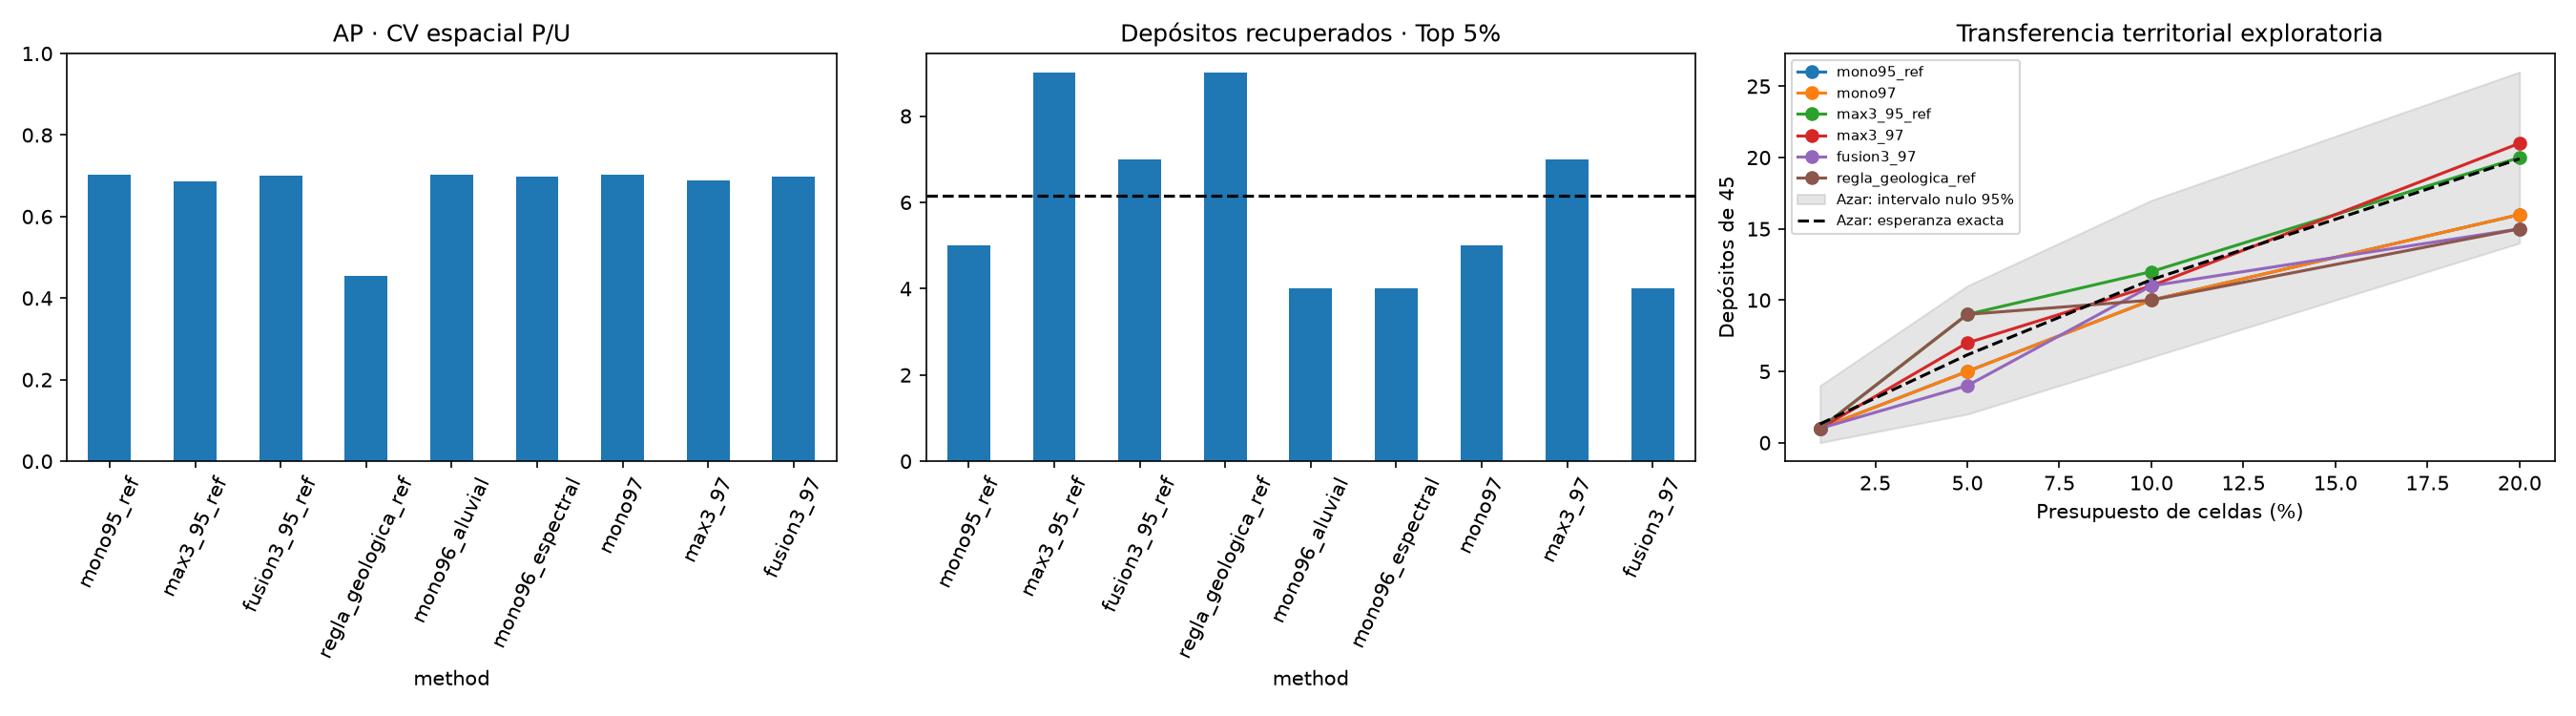

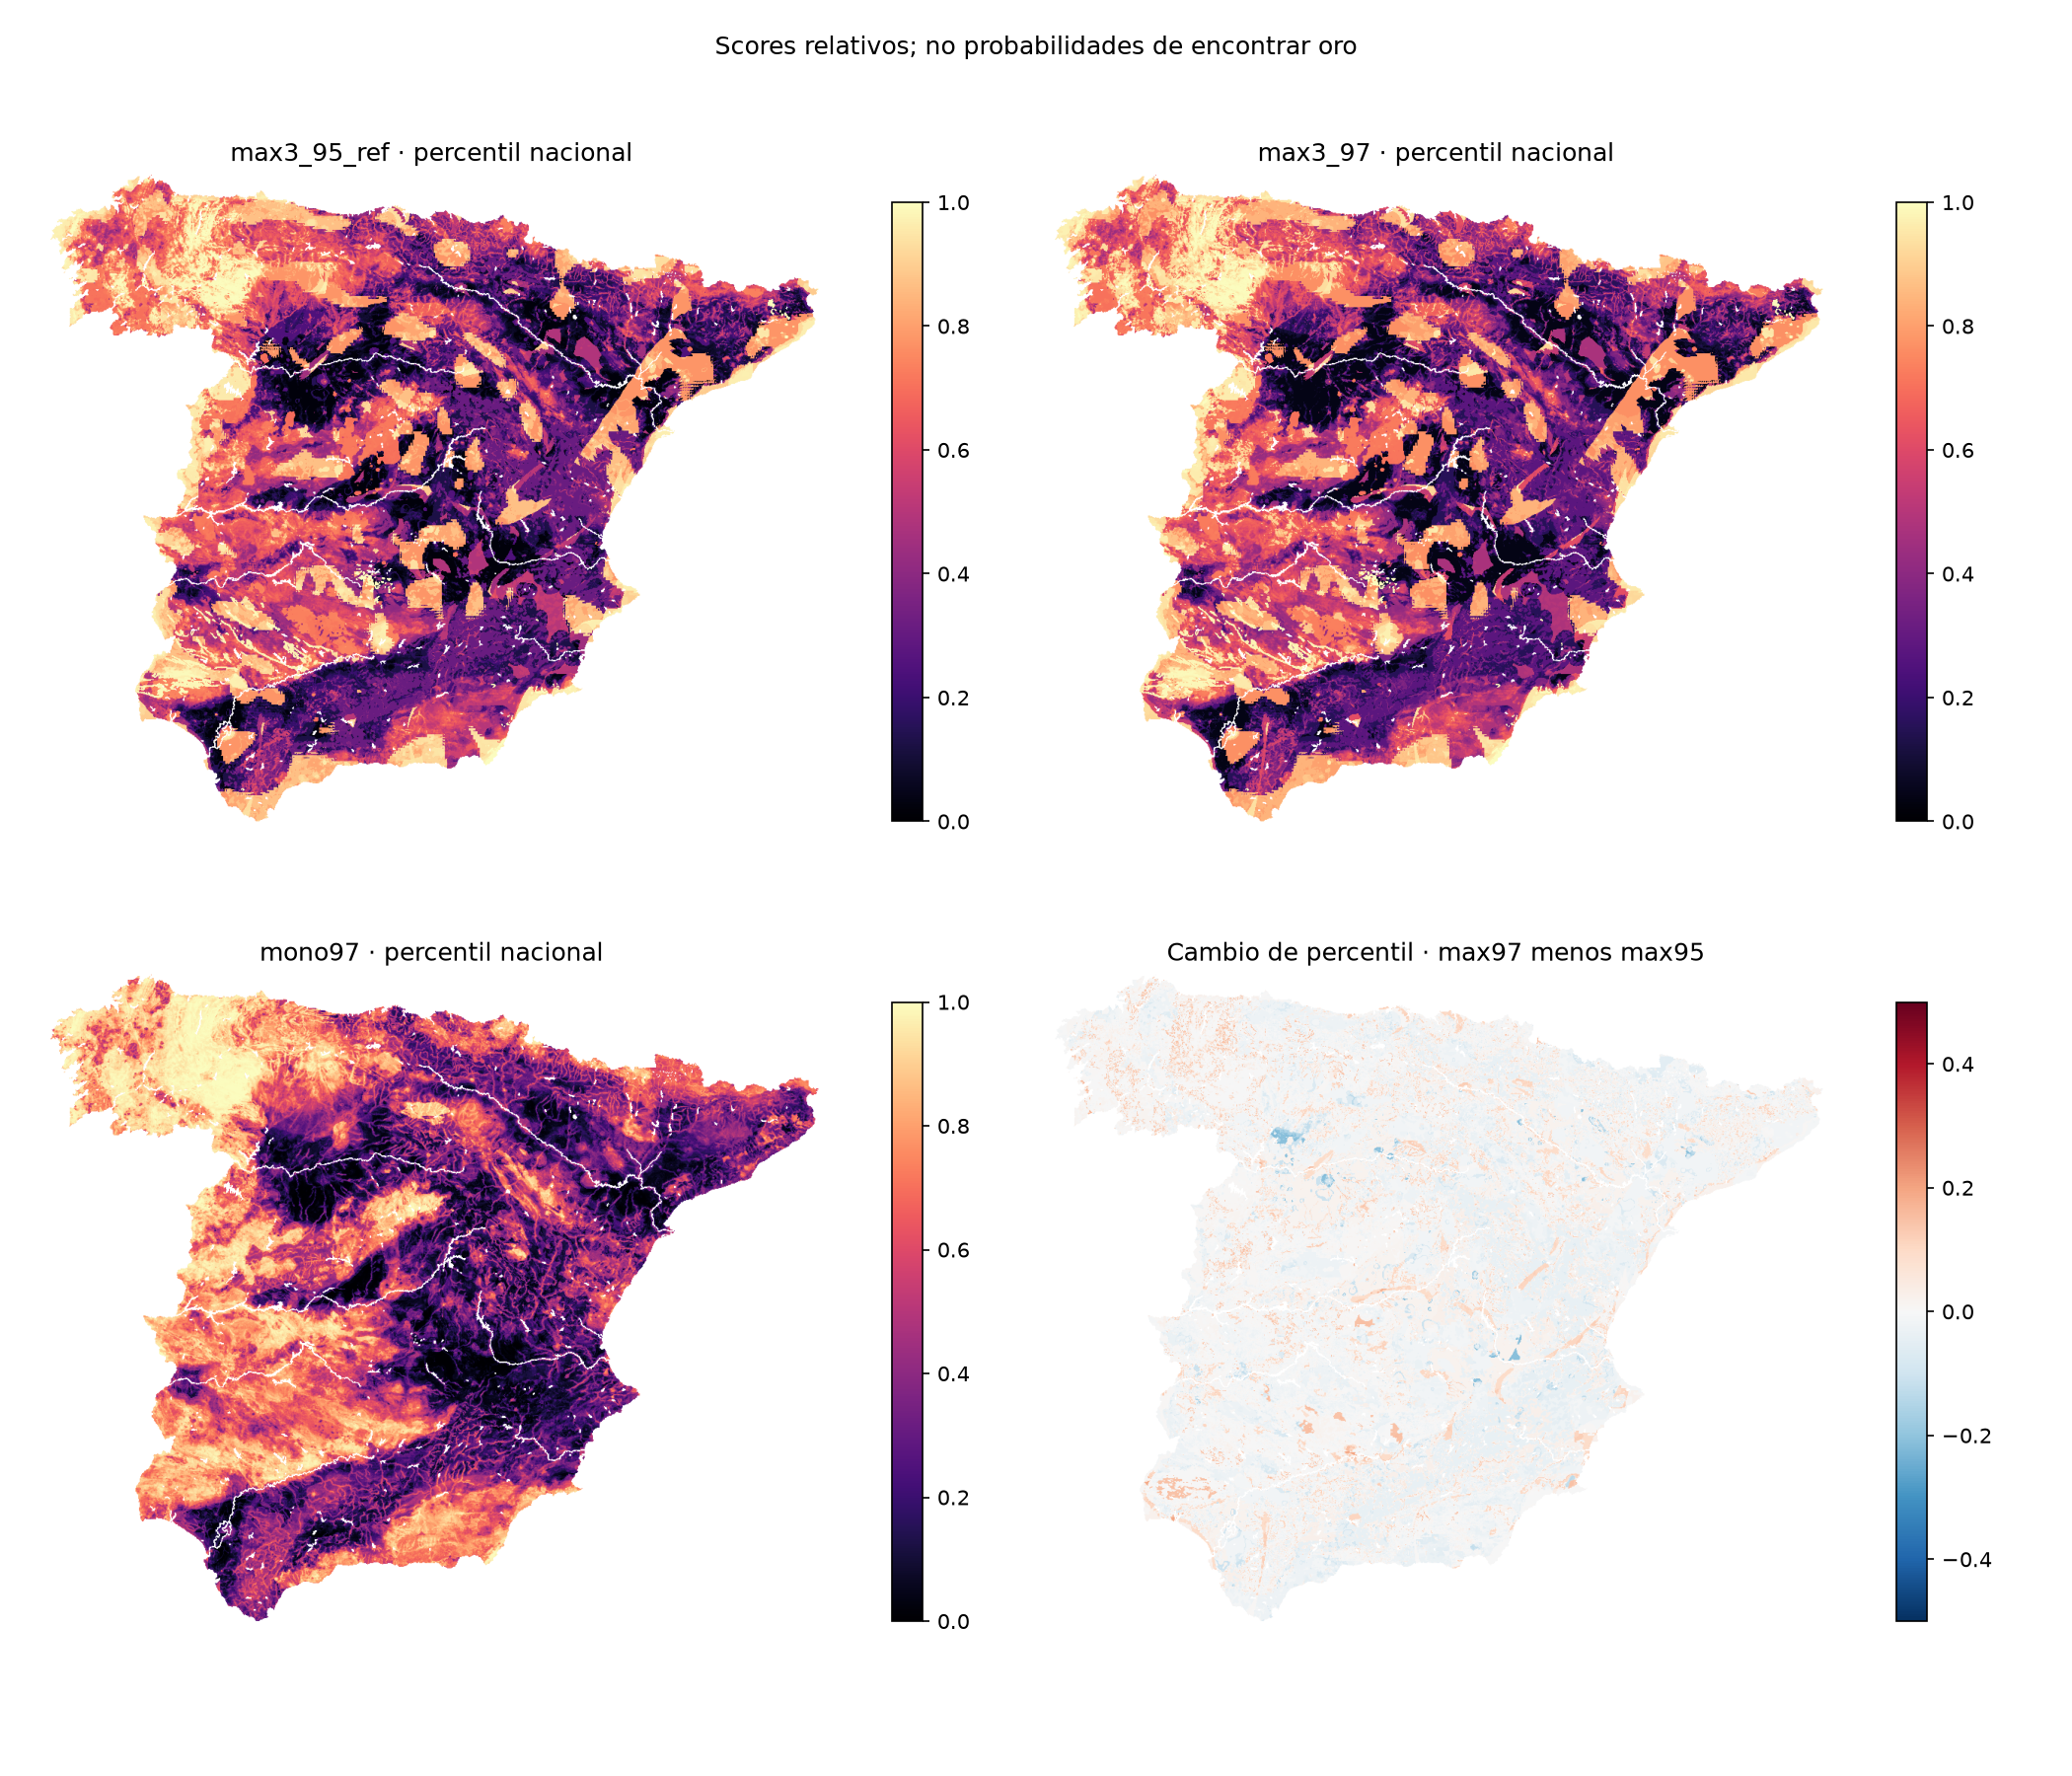

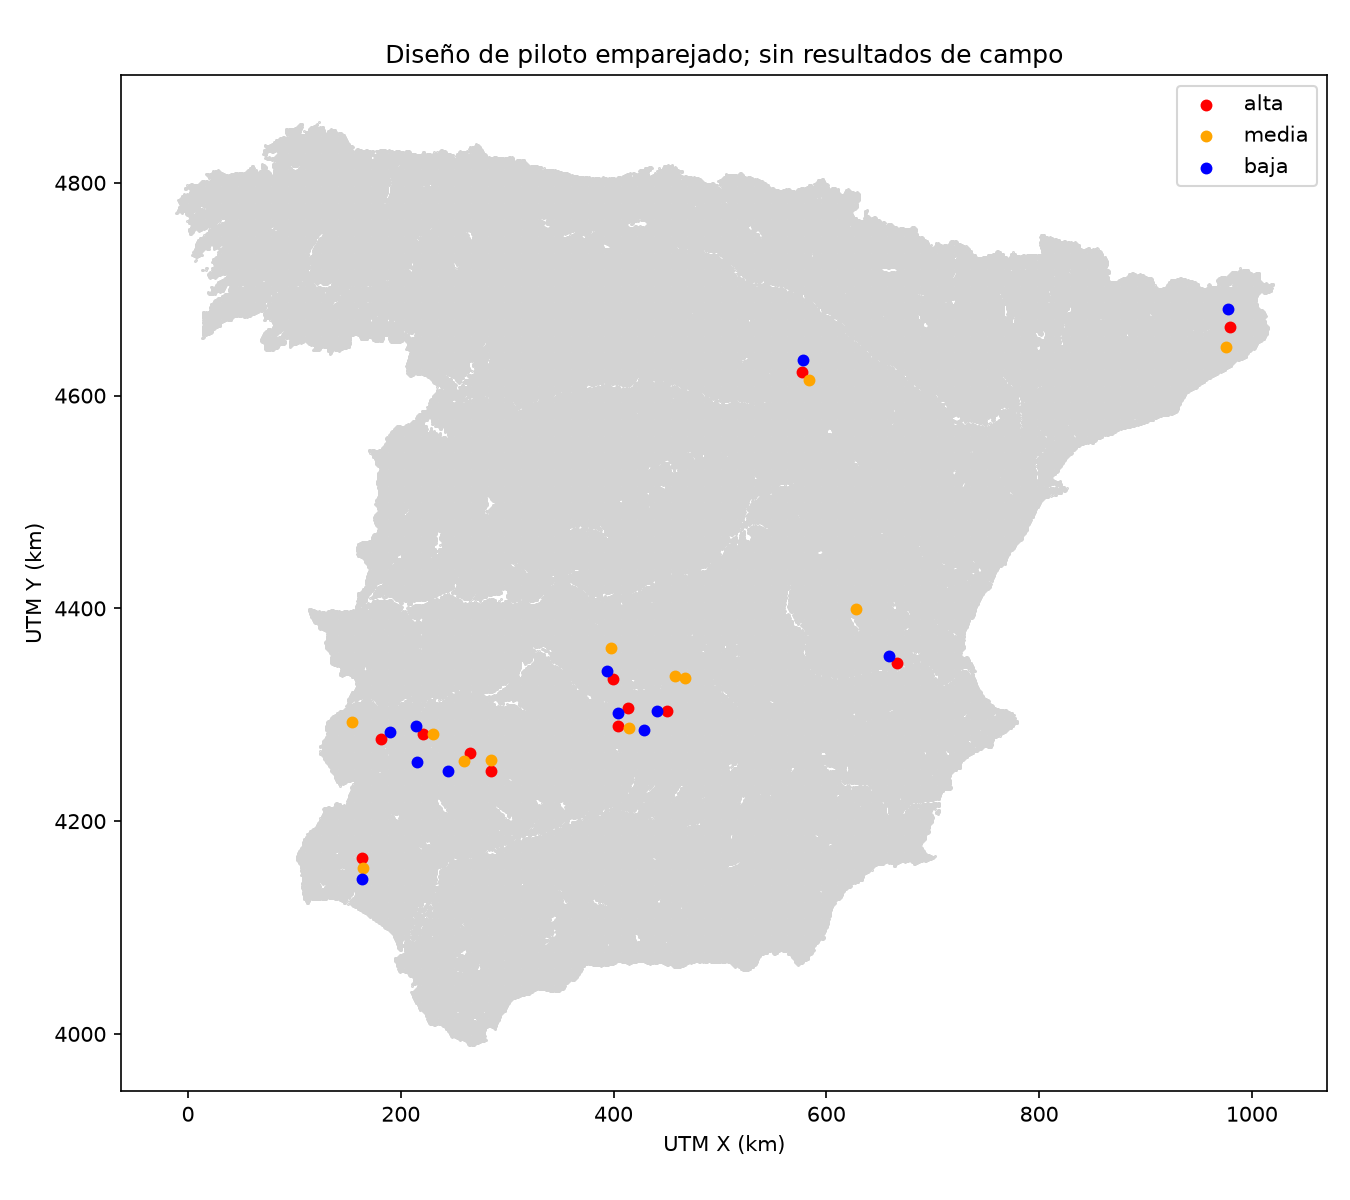

2026-10-22T16:25:11+00:00 NB29 ejecutado, validado y sellado


# NB29 · Descriptores corregidos, ablación y reentrenamiento real

Fecha local: 22 de octubre de 2026. Se ajustan modelos nuevos con 96/97 variables y se reutiliza únicamente el control NB27 verificado, con entorno, código común, particiones y muestras idénticos. Las salidas NB27/NB28 permanecen intactas. La versión nacional principal se fija como `max3_97` antes de obtener resultados; no se elige un ganador mirando el test.

## Qué se ha corregido

u000 no identifica terrazas: su leyenda es una unidad mixta de areniscas, conglomerados, arcillas, calizas y evaporitas. Se utiliza u012, gravas/conglomerados/arenas/limos, como contexto amplio. La fracción cuaternaria u004 es una copia exacta y no se duplica. El GPKG auxiliar tiene un único descriptor genérico y código geomorfológico 0; no permite acreditar terrazas y no se incorpora. Las fórmulas y constantes se fijan antes de entrenar en `contrato_descriptores_nb29.csv`. Son interacciones de covariables existentes, no nuevas mediciones.

El descriptor aluvial combina distancia a cauce, pendiente, u012 y TPI local. No se presenta como energía hidráulica ni como terraza observada. El espectral combina excesos de ratios MODIS con atenuación vegetal cuadrática; no se afirma adquisición Sentinel-2, QA nueva ni diagnóstico mineral. Los ausentes se conservan hasta la imputación de cada miembro. Pathfinder, medianas, escalas y categorías se ajustan con entrenamiento exclusivamente.

## Diseño y atribución

Muestra externa, cinco pliegues espaciales, siete reservas distritales y presupuestos 1/5/10/20% idénticos al control. Cada ajuste tiene ocho miembros y U:P=3:1 sin reemplazo. Las ablaciones `mono96_aluvial`, `mono96_espectral`, `mono97` comparten exactamente P/U, pesos e hiperparámetros con `mono95_ref`. Las ramas de 97 variables se comparan con los controles del mismo sistema y semillas. Los casos desconocidos permanecen en el global; epitermal se limita a cuatro celdas de dos depósitos documentados.

`max3_97` y `fusion3_97` agregan los mismos global97, primario_otro97, aluvial97 y epitermal97. Se conservan tres pliegues internos espaciales con buffer de 15 km para la CDF y selección de pesos por AP P/U. AP interna es un proxy de discriminación P/U, no optimización directa de recuperación por área. No se usan mínimos/máximos del test ni el factor 0,7.

### CV espacial P/U

| method | roc_auc | average_precision | positive_cell_recovery_at_05 | positive_cell_recovery_at_10 |
| --- | --- | --- | --- | --- |
| mono95_ref | 0.89490 | 0.70202 | 0.15739 | 0.31161 |
| max3_95_ref | 0.88999 | 0.68716 | 0.16057 | 0.31320 |
| fusion3_95_ref | 0.89410 | 0.69986 | 0.15580 | 0.31002 |
| regla_geologica_ref | 0.78513 | 0.45353 | 0.08267 | 0.18601 |
| mono96_aluvial | 0.89515 | 0.70185 | 0.15898 | 0.31002 |
| mono96_espectral | 0.89428 | 0.69888 | 0.16216 | 0.31002 |
| mono97 | 0.89563 | 0.70279 | 0.16057 | 0.31161 |
| max3_97 | 0.88911 | 0.68827 | 0.16057 | 0.31002 |
| fusion3_97 | 0.89220 | 0.69813 | 0.16057 | 0.31161 |

La muestra P/U no representa prevalencia nacional. Brier no acredita calibración física de los scores normalizados.

### Recuperación territorial

| method | n_deposits | captured_01 | captured_05 | captured_10 | captured_20 |
| --- | --- | --- | --- | --- | --- |
| mono95_ref | 45 | 1 | 5 | 10 | 16 |
| max3_95_ref | 45 | 1 | 9 | 12 | 20 |
| fusion3_95_ref | 45 | 0 | 7 | 10 | 15 |
| regla_geologica_ref | 45 | 1 | 9 | 10 | 15 |
| mono96_aluvial | 45 | 1 | 4 | 10 | 16 |
| mono96_espectral | 45 | 1 | 4 | 11 | 16 |
| mono97 | 45 | 1 | 5 | 10 | 16 |
| max3_97 | 45 | 1 | 7 | 11 | 21 |
| fusion3_97 | 45 | 1 | 4 | 11 | 15 |

### Referencia aleatoria e incertidumbre

| budget_percent | expected_deposits | simulation_mean | null_q025 | null_q975 | simulation_standard_error |
| --- | --- | --- | --- | --- | --- |
| 1 | 1.31547 | 1.31455 | 0.00000 | 4.00000 | 0.00793 |
| 5 | 6.16057 | 6.16470 | 2.00000 | 11.00000 | 0.01576 |
| 10 | 11.43462 | 11.42130 | 6.00000 | 17.00000 | 0.01967 |
| 20 | 19.90947 | 19.89550 | 14.00000 | 26.00000 | 0.02183 |

Se simulan 20.000 selecciones uniformes por presupuesto, conservando huellas multicelda y posibles celdas compartidas por depósitos mediante una hipergeométrica multivariante. Los intervalos nulos no son intervalos de confianza de la tasa de descubrimiento. Las colas Monte Carlo, guardadas por diagnóstico, son exploratorias y no se corrigen por búsqueda entre variantes.

Contraste principal predeclarado, max97 frente a max95 al 5%: **-2 depósitos**, diferencia de recuperación **-4.44 puntos porcentuales**, intervalo bootstrap pareado de siete grupos **[-8.70, 0.00]**. El intervalo exploratorio incluye cero; no se demuestra una mejora consistente entre territorios.

| contrast | budget_percent | delta_captured | delta_recovery_pp | ci025_pp | ci975_pp | bootstrap_unit | n_clusters |
| --- | --- | --- | --- | --- | --- | --- | --- |
| aluvial_vs_95 | 5 | -1 | -2.22222 | -6.97674 | 0.00000 | rotation_group | 7 |
| espectral_vs_95 | 5 | -1 | -2.22222 | -6.97674 | 0.00000 | rotation_group | 7 |
| ambos_vs_95 | 5 | 0 | 0.00000 | 0.00000 | 0.00000 | rotation_group | 7 |
| interaccion_descriptores | 5 | 2 | 4.44444 | 0.00000 | 13.95349 | rotation_group | 7 |
| max97_vs_max95 | 5 | -2 | -4.44444 | -8.69565 | 0.00000 | rotation_group | 7 |
| fusion97_vs_fusion95 | 5 | -3 | -6.66667 | -12.50000 | -2.17391 | rotation_group | 7 |
| max97_vs_mono97 | 5 | 2 | 4.44444 | -6.82215 | 15.90909 | rotation_group | 7 |

Los grupos ya se observaron durante NB19–28. Esta evaluación es exploratoria; un buen resultado no convierte la reserva en una prueba externa nueva. Siete grupos aportan una incertidumbre estimada con limitaciones. El término interacción en la tabla es un contraste de resultados de algoritmos; no demuestra causalidad geológica.



Informe: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\informes\reentrenamiento_nb29_descriptores_y_piloto_20261022\INFORME_NB29_DESCRIPTORES_Y_REENTRENAMIENTO.md
Modelo nacional: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_nb29_descriptores_y_piloto_20261022\partitions\national_0\model.joblib
Mapa principal: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_nb29_descriptores_y_piloto_20261022\maps\NB29_max3_97_score.tif


In [8]:
validacion = exp.validate()
display(pd.Series(validacion).to_frame('verificacion'))
for figura in exp.make_figures():
    display(Image(filename=str(figura)))
informe = exp.write_report()
exp.seal(informe)
display(Markdown(informe.read_text(encoding='utf-8').split('## Ajuste nacional')[0]))
print('Informe:', informe)
print('Modelo nacional:', exp.output / 'partitions/national_0/model.joblib')
print('Mapa principal:', exp.output / 'maps/NB29_max3_97_score.tif')
